# Lab 2 · Dense Variational Autoencoder for Faces

| Student | Roll number |
|---|---|
| Anant Arya | A24ARIU0014 |

The encoder predicts a diagonal Gaussian with 100 latent coordinates per face. The decoder learns to reconstruct faces from sampled latent vectors. This lab also tests what happens when the KL weight changes.

**Saved run.** The full LFW deep-funneled archive and PyTorch were unavailable in the execution environment. The saved results use NumPy/SciPy on the 100 real face crops in [scikit-image’s LFW subset](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.lfw_subset). The 25 × 25 grayscale crops were resized to 45 × 45 and repeated across three channels. The split is 80 training and 20 validation faces. Each model trained for 10 epochs with batch size 16. The full-data path uses PyTorch, RGB images and batch size 64.

**Full-data rerun.** On Kaggle, attach the course LFW dataset and set `RUN_MODE = "full"`. Locally, install PyTorch and point `LFW_DATASET_PATH` at the extracted `lfw-deepfunneled` directory. Then run all cells. To repeat the saved subset run, keep `RUN_MODE = "subset"`.

## 1. Environment and LFW data

In [1]:
# Full run dependencies: torch matplotlib numpy pandas scikit-learn pillow
# Subset run also uses scipy and threadpoolctl (installed with scikit-learn).
import base64
import os
import zlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.special import expit
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

RUN_MODE = "subset"  # "full" for the course's LFW deep-funneled archive
SEED = 42
IMAGE_SIZE = 45
CHANNELS = 3
INPUT_DIM = CHANNELS * IMAGE_SIZE * IMAGE_SIZE
LATENT_DIM = 100
EPOCHS = 10
LEARNING_RATE = 1e-3
BETA = 1.0
LOCAL_DATASET_PATH = Path("data/lfw-deepfunneled")

assert RUN_MODE in {"subset", "full"}
FULL_RUN = RUN_MODE == "full"
BATCH_SIZE = 64 if FULL_RUN else 16
if FULL_RUN:
    import torch
    from torch import nn
    import torch.nn.functional as F
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if DEVICE.type == "cpu":
        torch.set_num_threads(min(4, torch.get_num_threads()))
    print(f"Full LFW run | PyTorch on {DEVICE}")
else:
    blas_limit = threadpool_limits(limits=3, user_api="blas")
    print("LFW face-subset run | NumPy/SciPy on CPU")
print(f"Seed: {SEED} | Epochs: {EPOCHS} | Batch size: {BATCH_SIZE} | Learning rate: {LEARNING_RATE:g}")

LFW face-subset run | NumPy/SciPy on CPU
Seed: 42 | Epochs: 10 | Batch size: 16 | Learning rate: 0.001


In [2]:
# Bundled 100-face fallback. Source: scikit-image v0.25.2, skimage/data/lfw_subset.npy.
# The remaining 100 entries in the source are non-face patches and are excluded.
LFW_SUBSET_BYTES = (
    '...'
    'If3/AU+re9A='
)

Source: 100 grayscale LFW face crops, resized and replicated across RGB channels
Training images: 80 | Validation images: 20
Input array: (100, 3, 45, 45) | Flattened features per image: 6,075
Pixel range: [0.000, 1.000]


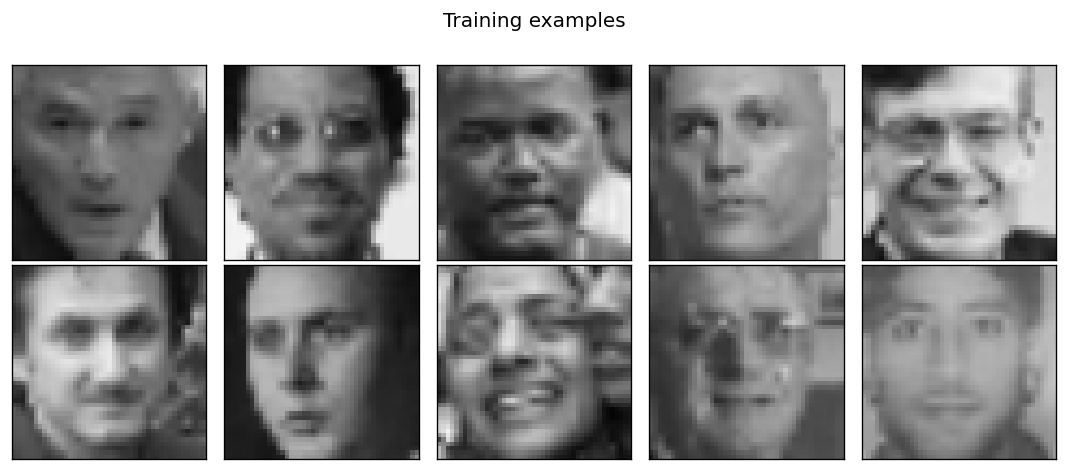

In [3]:
def resolve_lfw_root():
    env_path = os.environ.get("LFW_DATASET_PATH")
    candidates = []
    if env_path:
        candidates.append(Path(env_path).expanduser())
    if Path("/kaggle/input").exists():
        candidates.extend([
            Path("/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled"),
            Path("/kaggle/input/lfw-dataset"),
        ])
    candidates.extend([
        LOCAL_DATASET_PATH.expanduser(),
        Path("lfw-deepfunneled"),
    ])

    for root in candidates:
        if root.exists() and next(root.rglob("*.jpg"), None) is not None:
            return root
    checked = "\n".join(f"  - {path}" for path in candidates)
    raise FileNotFoundError(
        "No LFW .jpg files were found. Attach lfw-dataset on Kaggle, set "
        "LFW_DATASET_PATH, or edit LOCAL_DATASET_PATH. Checked:\n" + checked
    )


def resize_rgb(image):
    resized = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    return np.asarray(resized, dtype=np.float32).transpose(2, 0, 1) / 255


if FULL_RUN:
    dataset_root = resolve_lfw_root()
    image_paths = sorted(dataset_root.rglob("*.jpg"))
    image_df = pd.DataFrame({"path": image_paths, "person": [path.parent.name for path in image_paths]})
    # Keep the lab's balancing rule for the full archive.
    image_df = image_df.groupby("person", group_keys=False).filter(lambda rows: len(rows) < 25)
    data = []
    for path in image_df["path"]:
        with Image.open(path) as image:
            width, height = image.size
            mx = min(80, max(0, (width - 1) // 3))
            my = min(80, max(0, (height - 1) // 3))
            data.append(resize_rgb(image.crop((mx, my, width - mx, height - my))))
    faces = np.stack(data)
    print(f"Full-data directory: {dataset_root} | Identities after filtering: {image_df['person'].nunique():,}")
else:
    pixels = np.frombuffer(zlib.decompress(base64.b64decode(LFW_SUBSET_BYTES)), dtype=np.uint8)
    gray_faces = pixels.reshape(100, 25, 25)
    faces = np.stack([resize_rgb(Image.fromarray(face)) for face in gray_faces])
    print("Source: 100 grayscale LFW face crops, resized and replicated across RGB channels")

train_faces, val_faces = train_test_split(faces, test_size=0.2, random_state=SEED)
assert faces.shape[1:] == (CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
assert 0 <= faces.min() <= faces.max() <= 1
print(f"Training images: {len(train_faces):,} | Validation images: {len(val_faces):,}")
print(f"Input array: {faces.shape} | Flattened features per image: {INPUT_DIM:,}")
print(f"Pixel range: [{faces.min():.3f}, {faces.max():.3f}]")


def show_row(images, title, axes):
    for image, ax in zip(images, axes):
        ax.imshow(np.clip(image.transpose(1, 2, 0), 0, 1))
        ax.set_xticks([])
        ax.set_yticks([])
    if title:
        axes[0].set_ylabel(title)


fig, axes = plt.subplots(2, 5, figsize=(9, 4))
show_row(train_faces[:5], None, axes[0])
show_row(train_faces[5:10], None, axes[1])
fig.suptitle("Training examples")
fig.tight_layout()
plt.show()

## 2. From autoencoder to VAE

**1. What are the shapes of `mu`, `logvar` and `z`?** All three have shape `(N, 100)`. Each image has 100 means and 100 log variances, one for each coordinate of its diagonal Gaussian. One draw from that Gaussian gives 100 sampled coordinates per image.

**2. Why do the `mu` and `logvar` heads have no ReLU?** The mean can be anywhere on the real line. A negative log variance is also valid and corresponds to a variance between zero and one. ReLU would prevent negative means and impose a variance floor of one. The linear heads leave both quantities unconstrained, and exponentiation makes the variance positive.

**3. Why is ordinary backpropagation through a direct draw difficult?** A detached sampling operation such as `Normal(mu, sigma).sample()` gives backpropagation no differentiable path from the reconstruction loss to the distribution parameters. The KL term can still send its own gradients to the encoder. Reparameterization draws independent noise $\epsilon \sim \mathcal N(0,I)$, then computes $z=\mu+\exp(0.5\,\mathrm{logvar})\odot\epsilon$. For a fixed draw of $\epsilon$, the calculation is differentiable with respect to both heads. PyTorch’s `.rsample()` uses this idea.

## 3. Implement and check the probabilistic encoder

Both implementations use the same dense layers. The encoder has two linear heads and the decoder ends with a sigmoid. The subset implementation applies the same chain rule explicitly and checks both head gradients against finite differences.

In [4]:
if FULL_RUN:
    class DenseFaceVAE(nn.Module):
        def __init__(self, input_dim=INPUT_DIM, latent_dim=LATENT_DIM):
            super().__init__()
            self.input_dim = input_dim
            self.latent_dim = latent_dim
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, 1500),
                nn.ReLU(),
                nn.Linear(1500, 1000),
                nn.ReLU(),
            )

            # two heads on the same 1000 features (no activation on either)
            self.mu_head = nn.Linear(1000, latent_dim)       # mean of q(z|x)
            self.logvar_head = nn.Linear(1000, latent_dim)   # log of the variance of q(z|x)

            self.decoder = nn.Sequential(
                nn.Linear(latent_dim, 1000),
                nn.ReLU(),
                nn.Linear(1000, 1500),
                nn.ReLU(),
                nn.Linear(1500, input_dim),
                nn.Sigmoid(),
            )

        def encode(self, x):
            features = self.encoder(x.flatten(start_dim=1))
            return self.mu_head(features), self.logvar_head(features)

        def reparameterize(self, mu, logvar):
            # z = mu + sigma * eps
            sigma = torch.exp(0.5 * logvar)   # logvar = log(sigma^2), so sigma = e^(logvar / 2)
            eps = torch.randn_like(sigma)     # the only random part: N(0, 1), same shape as sigma
            z = mu + sigma * eps              # gradient flows to mu and sigma through this line
            return z

        def decode(self, z):
            pixels = self.decoder(z)
            return pixels.view(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

        def forward(self, x):
            # image -> (mu, logvar) -> random z -> rebuilt image
            mu, logvar = self.encode(x)
            z = self.reparameterize(mu, logvar)
            reconstruction = self.decode(z)
            return reconstruction, mu, logvar

In [5]:
if not FULL_RUN:
    class ArrayDenseFaceVAE:
        """NumPy implementation of the same dense VAE for the offline LFW subset."""

        def __init__(self, seed):
            self.rng = np.random.default_rng(seed)
            sizes = {
                "enc1": (INPUT_DIM, 1500), "enc2": (1500, 1000),
                "mu": (1000, LATENT_DIM), "logvar": (1000, LATENT_DIM),
                "dec1": (LATENT_DIM, 1000), "dec2": (1000, 1500),
                "out": (1500, INPUT_DIM),
            }
            self.params = {}
            for name, (n_in, n_out) in sizes.items():
                bound = 1 / np.sqrt(n_in)
                self.params[name + ".w"] = self.rng.uniform(-bound, bound, (n_in, n_out)).astype(np.float32)
                self.params[name + ".b"] = self.rng.uniform(-bound, bound, n_out).astype(np.float32)

        def linear(self, name, x):
            return x @ self.params[name + ".w"] + self.params[name + ".b"]

        def encoder_features(self, x):
            flat = x.reshape(len(x), INPUT_DIM)
            h1 = np.maximum(self.linear("enc1", flat), 0)
            h2 = np.maximum(self.linear("enc2", h1), 0)
            return flat, h1, h2

        def encode(self, x):
            _, _, h2 = self.encoder_features(x)
            return self.linear("mu", h2), self.linear("logvar", h2)

        def reparameterize(self, mu, logvar, rng=None):
            rng = self.rng if rng is None else rng
            noise = rng.standard_normal(mu.shape, dtype=np.float32)
            return mu + np.exp(0.5 * logvar) * noise

        def decoder_features(self, z):
            d1 = np.maximum(self.linear("dec1", z), 0)
            d2 = np.maximum(self.linear("dec2", d1), 0)
            return d1, d2, self.linear("out", d2)

        def decode(self, z):
            _, _, logits = self.decoder_features(z)
            return expit(logits).reshape(-1, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)

        def forward(self, x, rng=None):
            mu, logvar = self.encode(x)
            z = self.reparameterize(mu, logvar, rng)
            return self.decode(z), mu, logvar

        def loss_and_grads(self, x, beta, rng=None):
            flat, h1, h2 = self.encoder_features(x)
            mu = self.linear("mu", h2)
            logvar = self.linear("logvar", h2)
            z = self.reparameterize(mu, logvar, rng)
            d1, d2, logits = self.decoder_features(z)
            probs = expit(logits)
            var = np.exp(logvar)
            n = len(x)
            # BCE of sigmoid(logits), evaluated in a numerically stable form.
            bce = np.sum(np.logaddexp(0, logits) - flat * logits, dtype=np.float64) / n
            kl = 0.5 * np.sum(var + mu**2 - 1 - logvar, dtype=np.float64) / n
            grads = {}

            def linear_backward(name, inputs, delta):
                grads[name + ".w"] = inputs.T @ delta
                grads[name + ".b"] = delta.sum(axis=0)
                return delta @ self.params[name + ".w"].T

            grad_d2 = linear_backward("out", d2, (probs - flat) / n)
            grad_d1 = linear_backward("dec2", d1, grad_d2 * (d2 > 0))
            grad_z = linear_backward("dec1", z, grad_d1 * (d1 > 0))
            # dz/dmu = 1 and dz/dlogvar = 0.5 * (z - mu).
            grad_mu = grad_z + (beta / n) * mu
            grad_logvar = 0.5 * grad_z * (z - mu) + (0.5 * beta / n) * (var - 1)
            grad_h2 = linear_backward("mu", h2, grad_mu)
            grad_h2 += linear_backward("logvar", h2, grad_logvar)
            grad_h1 = linear_backward("enc2", h1, grad_h2 * (h2 > 0))
            linear_backward("enc1", flat, grad_h1 * (h1 > 0))
            return (bce + beta * kl, bce, kl), grads


    class ArrayAdam:
        def __init__(self, params, lr):
            self.params = params
            self.lr = lr
            self.first = {key: np.zeros_like(value) for key, value in params.items()}
            self.second = {key: np.zeros_like(value) for key, value in params.items()}
            self.step_number = 0

        def step(self, grads):
            self.step_number += 1
            correction1 = 1 - 0.9**self.step_number
            correction2 = 1 - 0.999**self.step_number
            for key, grad in grads.items():
                first = self.first[key]
                second = self.second[key]
                first *= 0.9
                first += 0.1 * grad
                second *= 0.999
                second += 0.001 * grad**2
                self.params[key] -= self.lr * (first / correction1) / (np.sqrt(second / correction2) + 1e-8)

## 4. Implement and check the negative ELBO

The objective per image is pixelwise binary cross-entropy plus $\beta$ times the KL divergence. For a diagonal Gaussian posterior and a unit-normal prior, $\mathrm{KL}=-\tfrac12\sum_j(1+\mathrm{logvar}_j-\mu_j^2-e^{\mathrm{logvar}_j})$. Sum each term over the batch and divide by the number of images. At $\beta=1$ this is the negative ELBO. In the PyTorch implementation the two reported terms are detached and the training loss retains its gradient.

In [6]:
if FULL_RUN:
    def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
        batch_size = target.size(0)

        # Part 1: reconstruction error, summed over every pixel, per image
        recon_loss = F.binary_cross_entropy(reconstruction, target, reduction="sum") / batch_size

        # Part 2: KL( N(mu, sigma^2) || N(0, 1) ), summed over the 100 dims, per image
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size

        total = recon_loss + beta * kl_loss       # keep the graph: we backprop through this
        return total, recon_loss.detach(), kl_loss.detach()
else:
    def vae_loss(reconstruction, target, mu, logvar, beta=1.0):
        p = np.clip(reconstruction.astype(np.float64), 1e-12, 1 - 1e-12)
        n = len(target)
        bce = -np.sum(target * np.log(p) + (1 - target) * np.log1p(-p)) / n
        kl = -0.5 * np.sum(1 + logvar - mu**2 - np.exp(logvar), dtype=np.float64) / n
        return bce + beta * kl, bce, kl

In [7]:
def create_model():
    if FULL_RUN:
        torch.manual_seed(SEED)
        return DenseFaceVAE().to(DEVICE)
    return ArrayDenseFaceVAE(SEED)


def on_device(values):
    return torch.as_tensor(values, device=DEVICE) if FULL_RUN else values


def to_array(values):
    return values.detach().cpu().numpy() if FULL_RUN else values


check_model = create_model()
batch = on_device(train_faces[:4])
reconstruction, mu, logvar = check_model.forward(batch)
z1 = check_model.reparameterize(mu, logvar)
z2 = check_model.reparameterize(mu, logvar)
assert reconstruction.shape == batch.shape
assert mu.shape == logvar.shape == z1.shape == (4, LATENT_DIM)
assert 0 <= reconstruction.min() <= reconstruction.max() <= 1
assert not np.array_equal(to_array(z1), to_array(z2))

for label, value in [
    ("input", batch), ("flattened", batch.reshape(4, -1)), ("mu", mu),
    ("logvar", logvar), ("z", z1), ("reconstruction", reconstruction),
]:
    print(f"{label:15} {tuple(value.shape)}")
parameters = (sum(p.numel() for p in check_model.parameters()) if FULL_RUN
              else sum(p.size for p in check_model.params.values()))
print(f"Trainable parameters: {parameters:,}")

if FULL_RUN:
    z1.mean().backward()
    assert check_model.mu_head.weight.grad.abs().sum() > 0
    assert check_model.logvar_head.weight.grad.abs().sum() > 0
    x = torch.full_like(batch, 0.5)
    zeros = torch.zeros_like(mu)
    assert not vae_loss(x, x, zeros, zeros)[0].requires_grad
    assert vae_loss(reconstruction, batch, mu, logvar)[0].requires_grad
else:
    def rng():
        return np.random.default_rng(18)

    def fixed_draw_loss(model, batch):
        pred, mean, logvar = model.forward(batch, rng=rng())
        return vae_loss(pred, batch, mean, logvar)[0]

    values, grads = check_model.loss_and_grads(batch, beta=1, rng=rng())
    pred, cm, cv = check_model.forward(batch, rng=rng())
    np.testing.assert_allclose(values, vae_loss(pred, batch, cm, cv), rtol=2e-5)
    for name in ("mu.w", "logvar.w"):
        weights = check_model.params[name]
        index = np.unravel_index(np.argmax(np.abs(grads[name])), weights.shape)
        initial = weights[index]
        delta = 0.002
        weights[index] = initial + delta
        plus = fixed_draw_loss(check_model, batch)
        weights[index] = initial - delta
        minus = fixed_draw_loss(check_model, batch)
        weights[index] = initial
        numerical = (plus - minus) / (2 * delta)
        analytic = float(grads[name][index])
        np.testing.assert_allclose(analytic, numerical, rtol=0.04, atol=0.002)
        print(f"{name:9} analytic gradient {analytic:+.5f} | finite difference {numerical:+.5f}")
    x = np.full_like(batch, 0.5)
    zeros = np.zeros_like(mu)

total, bce, kl = vae_loss(x, x, zeros, zeros)
assert abs(float(kl)) < 1e-6
assert abs(float(bce) - INPUT_DIM * np.log(2)) < 0.002
print(f"Unit-normal check: BCE {float(bce):.2f} | KL {float(kl):.4f}")
print("Model and loss checks passed.")
del check_model, reconstruction, mu, logvar, z1, z2

input           (4, 3, 45, 45)
flattened       (4, 6075)
mu              (4, 100)
logvar          (4, 100)
z               (4, 100)
reconstruction  (4, 3, 45, 45)
Trainable parameters: 21,536,275
mu.w      analytic gradient +0.10090 | finite difference +0.10095
logvar.w  analytic gradient +0.17524 | finite difference +0.17531
Unit-normal check: BCE 4210.87 | KL -0.0000
Model and loss checks passed.


## 5. Train the VAE

Each step samples a latent vector, computes reconstruction and KL losses, backpropagates, and updates the weights with Adam. Epoch metrics are weighted by the number of examples in each batch.

In [8]:
def train_step(model, batch, optimizer, beta):
    if FULL_RUN:
        batch = on_device(batch)
        optimizer.zero_grad(set_to_none=True)
        reconstruction, mu, logvar = model(batch)
        total, bce, kl = vae_loss(reconstruction, batch, mu, logvar, beta)
        total.backward()
        optimizer.step()
        return total.item(), bce.item(), kl.item()
    values, gradients = model.loss_and_grads(batch, beta)
    optimizer.step(gradients)
    return values


def evaluate(model, faces, beta):
    totals = np.zeros(3, dtype=np.float64)
    eval_rng = np.random.default_rng(SEED + 1)
    if FULL_RUN:
        model.eval()
    for start in range(0, len(faces), BATCH_SIZE):
        batch = on_device(faces[start:start + BATCH_SIZE])
        eps = on_device(eval_rng.standard_normal((len(batch), LATENT_DIM), dtype=np.float32))
        if FULL_RUN:
            with torch.no_grad():
                mu, logvar = model.encode(batch)
                prediction = model.decode(mu + torch.exp(0.5 * logvar) * eps)
                values = vae_loss(prediction, batch, mu, logvar, beta)
        else:
            mu, logvar = model.encode(batch)
            prediction = model.decode(mu + np.exp(0.5 * logvar) * eps)
            values = vae_loss(prediction, batch, mu, logvar, beta)
        totals += np.asarray([float(value) for value in values]) * len(batch)
    return totals / len(faces)


def train_vae(beta):
    model = create_model()
    if FULL_RUN:
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    else:
        optimizer = ArrayAdam(model.params, LEARNING_RATE)
    shuffle_rng = np.random.default_rng(SEED)
    history = []
    print(f"β = {beta:g}")
    for epoch in range(1, EPOCHS + 1):
        if FULL_RUN:
            model.train()
        indices = shuffle_rng.permutation(len(train_faces))
        running_total = 0.0
        for start in range(0, len(indices), BATCH_SIZE):
            batch = train_faces[indices[start:start + BATCH_SIZE]]
            total, _, _ = train_step(model, batch, optimizer, beta)
            running_total += total * len(batch)
        train_total = running_total / len(indices)
        val_total, val_bce, val_kl = evaluate(model, val_faces, beta)
        assert np.isfinite([train_total, val_total, val_bce, val_kl]).all()
        history.append((epoch, train_total, val_total, val_bce, val_kl))
        print(f"Epoch {epoch:02d} | Train {train_total:8.2f} | Val {val_total:8.2f} | "
              f"Val BCE {val_bce:8.2f} | Val KL {val_kl:7.2f}")
    return model, pd.DataFrame(history, columns=["epoch", "train", "val", "bce", "kl"])


model, history = train_vae(BETA)

β = 1
Epoch 01 | Train  4135.78 | Val  4093.91 | Val BCE  4091.00 | Val KL    2.91
Epoch 02 | Train  4059.28 | Val  4080.31 | Val BCE  4076.13 | Val KL    4.18
Epoch 03 | Train  4048.40 | Val  4041.17 | Val BCE  4036.58 | Val KL    4.59
Epoch 04 | Train  4031.83 | Val  4028.24 | Val BCE  4016.57 | Val KL   11.67
Epoch 05 | Train  4010.97 | Val  4015.16 | Val BCE  4002.57 | Val KL   12.59
Epoch 06 | Train  4003.66 | Val  4010.36 | Val BCE  3996.75 | Val KL   13.61
Epoch 07 | Train  3992.08 | Val  4006.92 | Val BCE  3996.25 | Val KL   10.67
Epoch 08 | Train  3984.06 | Val  3997.08 | Val BCE  3986.70 | Val KL   10.38
Epoch 09 | Train  3988.99 | Val  3989.36 | Val BCE  3977.79 | Val KL   11.57
Epoch 10 | Train  3997.52 | Val  4005.42 | Val BCE  3989.21 | Val KL   16.21


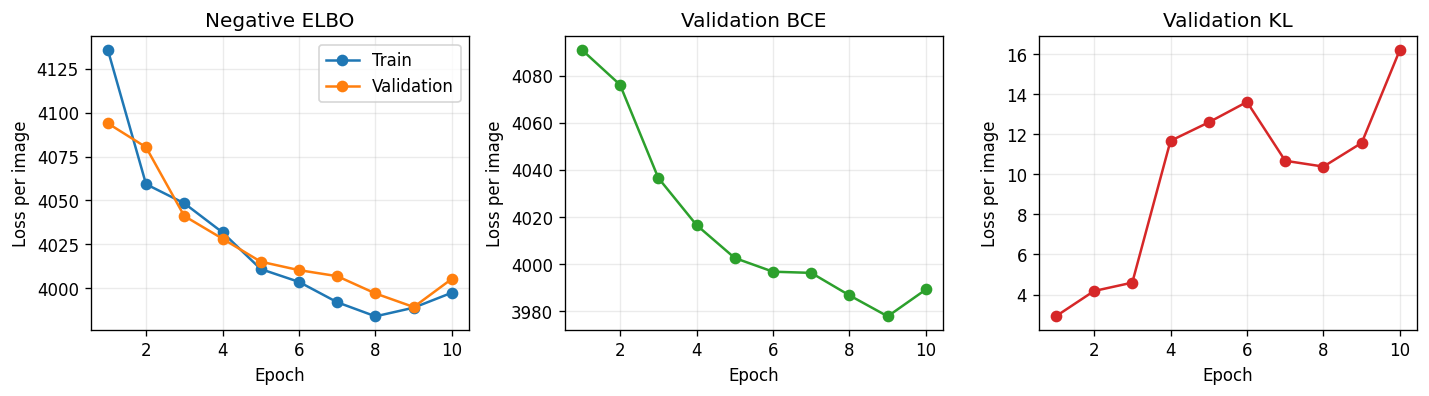

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(history.epoch, history.train, marker="o", label="Train")
axes[0].plot(history.epoch, history.val, marker="o", label="Validation")
axes[0].set_title("Negative ELBO")
axes[0].legend()
axes[1].plot(history.epoch, history.bce, marker="o", color="tab:green")
axes[1].set_title("Validation BCE")
axes[2].plot(history.epoch, history.kl, marker="o", color="tab:red")
axes[2].set_title("Validation KL")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss per image")
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**What the saved curves show.** At β = 1, the validation negative ELBO dropped from 4093.91 in epoch 1 to 3989.36 in epoch 9, then rose to 4005.42 in epoch 10. Reconstruction BCE accounts for most of the total and follows a similar pattern. Validation KL rose from 2.91 to 16.21 with fluctuations, indicating that the encoded distributions moved farther from the prior on average. The training and validation curves remained close on this split, although 20 validation faces give a limited estimate of generalization.

## 6. Inspect reconstructions

Decode the posterior mean so the same input gives the same reconstruction each time.

Originals: (8, 3, 45, 45) | Reconstructions: (8, 3, 45, 45)


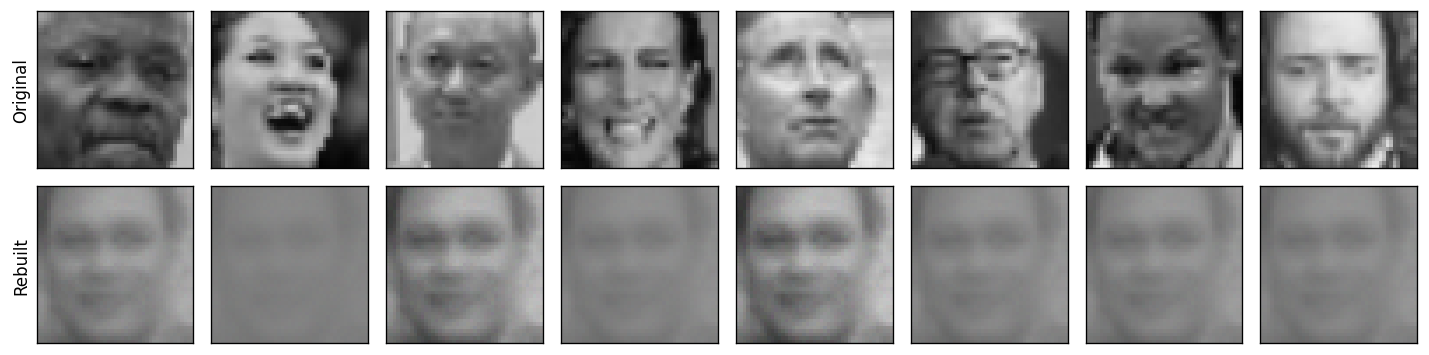

In [10]:
def reconstruct(model, images):
    if FULL_RUN:
        model.eval()
        with torch.no_grad():
            return to_array(model.decode(model.encode(on_device(images))[0]))
    return model.decode(model.encode(images)[0])


def generate(model, z):
    if FULL_RUN:
        model.eval()
        with torch.no_grad():
            return to_array(model.decode(on_device(z)))
    return model.decode(z)


comparison_faces = val_faces[:8]
reconstructed_faces = reconstruct(model, comparison_faces)
print(f"Originals: {comparison_faces.shape} | Reconstructions: {reconstructed_faces.shape}")
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
show_row(comparison_faces, "Original", axes[0])
show_row(reconstructed_faces, "Rebuilt", axes[1])
fig.tight_layout()
plt.show()

**Originals versus reconstructions in the saved run**

| Aspect | Observation |
|---|---|
| Identity | The decoder recovered a broad face shape in several columns, but different people often produced very similar reconstructions. |
| Pose | Some images kept rough placement of the eyes and mouth. Head turns and expressions were weak. The open mouth in the second original nearly disappeared. |
| Colour and brightness | The subset is grayscale, so it only lets us compare brightness. Some large bright and dark regions survived, and several reconstructions had very low contrast. |
| Fine detail | Glasses, teeth and facial hair were mostly lost. The reconstructions were visibly blurrier than the originals. |

## 7. Generate new faces

Draw ten independent vectors from $\mathcal N(0,I)$ and decode them directly.

Prior latents: (10, 100) | Generated faces: (10, 3, 45, 45)


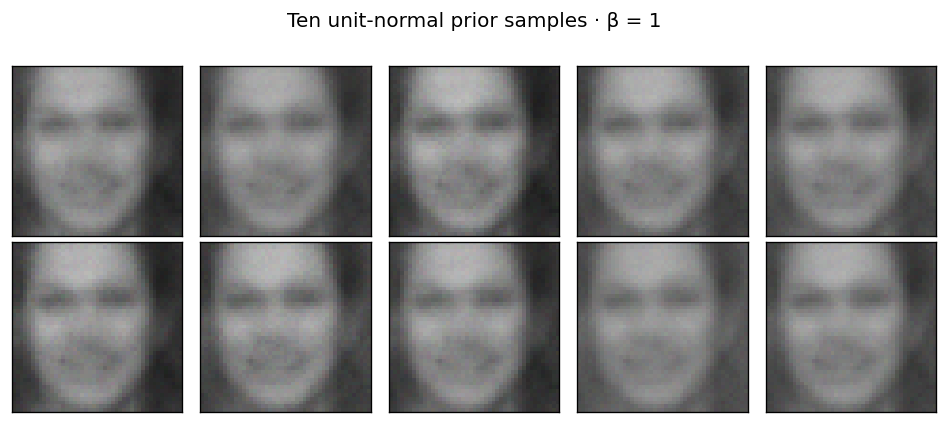

In [11]:
prior_rng = np.random.default_rng(SEED + 2)
z_prior = prior_rng.standard_normal((10, LATENT_DIM), dtype=np.float32)
generated_faces = generate(model, z_prior)
assert generated_faces.shape == (10, 3, 45, 45)
print(f"Prior latents: {z_prior.shape} | Generated faces: {generated_faces.shape}")
fig, axes = plt.subplots(2, 5, figsize=(8, 3.6))
show_row(generated_faces[:5], None, axes[0])
show_row(generated_faces[5:], None, axes[1])
fig.suptitle("Ten unit-normal prior samples · β = 1")
fig.tight_layout()
plt.show()

**What the saved samples show.** The ten draws produced rough face-like patterns with dark eye regions and a lighter central face. They differ slightly in brightness and mouth shape but are blurry and similar overall. The KL term encouraged the training posteriors to overlap with the prior, which helps the decoder produce plausible coarse structure from prior draws.

## 8. Experiment · What does β control?

Train fresh models at β = 0 and β = 4 and compare them with the β = 1 baseline. All three start from the same initialization and see the same batches in the same order. Validation uses a fixed set of posterior draws. The plots compare posterior-mean reconstructions for the same eight validation faces and prior samples from the same eight latent vectors.

In [12]:
beta_models = {1.0: model}
beta_histories = {1.0: history}
for beta in (0.0, 4.0):
    beta_models[beta], beta_histories[beta] = train_vae(beta)

rows = []
for beta, metrics in sorted(beta_histories.items()):
    final = metrics.iloc[-1]
    rows.append({"β": beta, "Validation BCE": final.bce, "Validation KL": final.kl})
results_df = pd.DataFrame(rows).set_index("β")
print("\nFinal validation metrics per image")
print(results_df.to_string(float_format=lambda value: f"{value:.2f}"))

β = 0
Epoch 01 | Train  4404.16 | Val  4159.54 | Val BCE  4159.54 | Val KL    4.74
Epoch 02 | Train  4114.47 | Val  4122.97 | Val BCE  4122.97 | Val KL   11.63
Epoch 03 | Train  4056.56 | Val  4088.13 | Val BCE  4088.13 | Val KL    7.48
Epoch 04 | Train  4055.30 | Val  4080.09 | Val BCE  4080.09 | Val KL   11.70
Epoch 05 | Train  4042.69 | Val  4063.68 | Val BCE  4063.68 | Val KL    9.71
Epoch 06 | Train  4030.44 | Val  4040.50 | Val BCE  4040.50 | Val KL   21.32
Epoch 07 | Train  4002.68 | Val  4020.20 | Val BCE  4020.20 | Val KL   37.44
Epoch 08 | Train  3998.29 | Val  4022.68 | Val BCE  4022.68 | Val KL   62.58
Epoch 09 | Train  3988.05 | Val  4009.66 | Val BCE  4009.66 | Val KL   65.40
Epoch 10 | Train  3986.67 | Val  3999.00 | Val BCE  3999.00 | Val KL   83.87
β = 4
Epoch 01 | Train  4158.37 | Val  4107.78 | Val BCE  4098.44 | Val KL    2.34
Epoch 02 | Train  4065.77 | Val  4087.59 | Val BCE  4084.14 | Val KL    0.86
Epoch 03 | Train  4060.99 | Val  4070.34 | Val BCE  4066.60 | Va

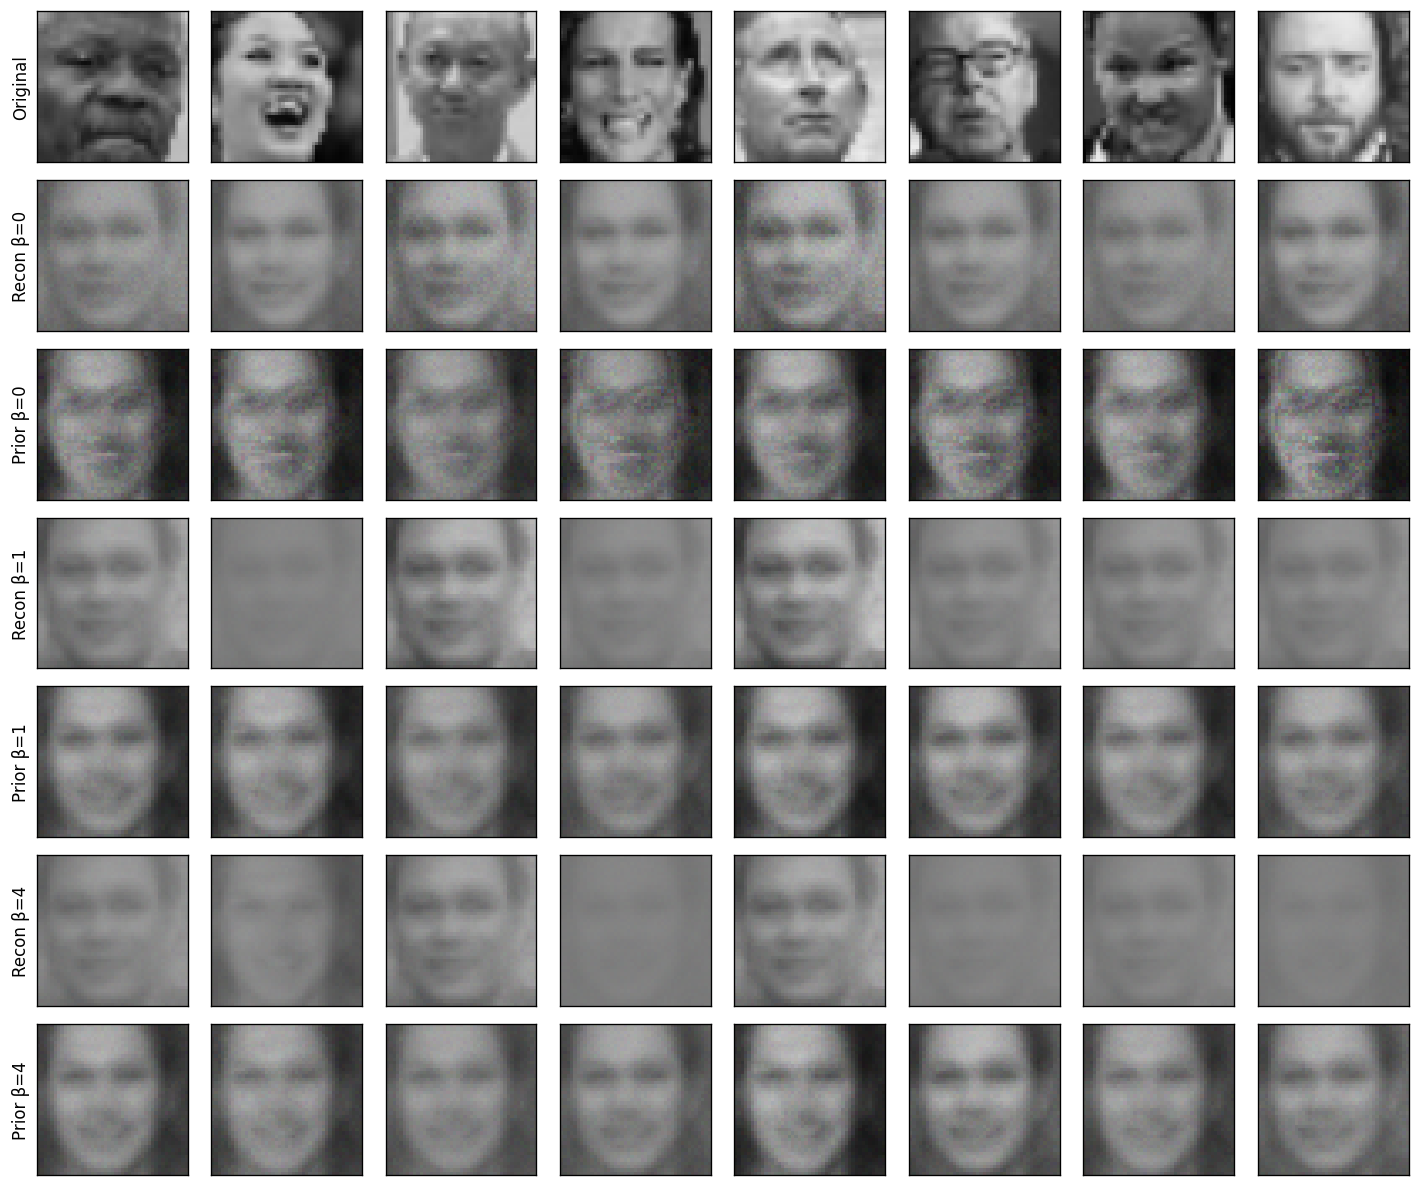

In [13]:
shared_z = np.random.default_rng(0).standard_normal((8, LATENT_DIM), dtype=np.float32)
fig, axes = plt.subplots(7, 8, figsize=(12, 10))
show_row(comparison_faces, "Original", axes[0])
for i, (beta, vae) in enumerate(sorted(beta_models.items())):
    row = 1 + 2 * i
    show_row(reconstruct(vae, comparison_faces), f"Recon β={beta:g}", axes[row])
    show_row(generate(vae, shared_z), f"Prior β={beta:g}", axes[row + 1])
fig.tight_layout()
plt.show()

**Final validation results from the saved run** (per image)

| β | Reconstruction BCE ↓ | KL ↓ | Prior samples |
|---:|---:|---:|---|
| 0 | 3999.00 | 83.87 | Still face-like in outline, with much more speckling and irregular detail. |
| 1 | 3989.21 | 16.21 | Smoother face shapes with blurry features and modest variation. |
| 4 | 3994.46 | 4.07 | Smooth, similar faces with modest differences around the mouth and in brightness. |

**1. What happens at β = 0?** The objective reduces to reconstruction BCE. The encoder can move the means or shrink the variances whenever that helps reconstruction, with no KL penalty for deviating from $\mathcal N(0,I)$. The decoder trains on samples from these posteriors, so it has less incentive to decode prior draws well. In this run, β = 0 had the highest measured KL, and its prior samples were visibly noisier.

**2. How does increasing β affect reconstruction and prior samples?** A larger β penalizes posterior deviations from the prior more strongly, so posteriors tend to overlap more and may carry less information about each input. This can erase identity and fine detail in reconstructions while making prior draws more consistent. In this run the KL decreased at each step, from 83.87 to 16.21 to 4.07. Reconstruction BCE was lowest at β = 1, then rose slightly at β = 4. The sampled faces became smoother from β = 0 to β = 1 or 4, and both regularized models had limited variety. Validation BCE did not change monotonically in this experiment.

**3. Why can a VAE use dense layers, and what do they lose for images?** The defining operations are a probabilistic encoder, reparameterized sampling, a decoder and the reconstruction-plus-KL objective. Linear layers can implement both encoder and decoder. Flattening keeps the individual pixel values, but the dense network has no built-in notion of which pixels are neighbors or how to reuse a detector across locations. For example, the first layer alone uses $6075\times1500=9{,}112{,}500$ weights before biases. Convolutional filters share weights across locations and exploit local image structure.

## Optional extension · Interpolate between two faces

Encode two validation faces and linearly interpolate between their means. The decoder sees $z(t)=(1-t)\mu_A+t\mu_B$, with $t$ ranging from zero to one.

Interpolation t: [0.   0.14 0.29 0.43 0.57 0.71 0.86 1.  ]


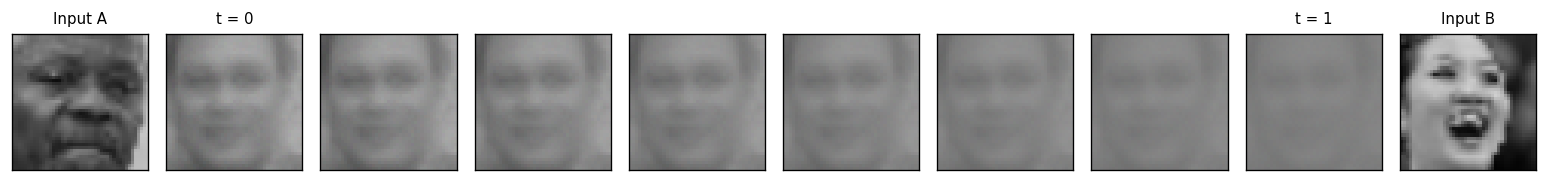

In [14]:
if FULL_RUN:
    with torch.no_grad():
        mu_pair = to_array(model.encode(on_device(comparison_faces[:2]))[0])
else:
    mu_pair = model.encode(comparison_faces[:2])[0]
steps = np.linspace(0, 1, 8, dtype=np.float32)[:, None]
path = (1 - steps) * mu_pair[0] + steps * mu_pair[1]
morph = generate(model, path)
print("Interpolation t:", np.round(steps[:, 0], 2))
fig, axes = plt.subplots(1, 10, figsize=(13, 1.9))
show_row(comparison_faces[:1], None, axes[:1])
show_row(morph, None, axes[1:9])
show_row(comparison_faces[1:2], None, axes[9:])
axes[0].set_title("Input A", fontsize=9)
axes[1].set_title("t = 0", fontsize=9)
axes[8].set_title("t = 1", fontsize=9)
axes[9].set_title("Input B", fontsize=9)
fig.tight_layout()
plt.show()

**Observation.** The decoded path gradually fades from a visible facial pattern at the first mean toward a lower-contrast pattern at the second. The intermediate outputs change smoothly along this line, though the second endpoint captures little of the original expression. Both endpoints are reconstructions decoded from posterior means.